# XTX / SANOS：从报价到曲面

本 notebook 展示基础复现的每一步，读取已保存结果，不自动运行校准。默认日期为2025-06-02。所有市场点均来自实际校准输入。研究参数和限制见根目录 README。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/sanos_core.py').exists())
sys.path[:0] = [str(ROOT/'src'), str(ROOT/'scripts')]
import numpy as np
import pandas as pd
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import display, Image
from diagnose_xtx_wing_turns import otm, iv
get_ipython().run_line_magic('matplotlib', 'inline')
DATE='2025-06-02'
BLOCK='june'
MODEL_DIR=ROOT/'data/outputs/daily_validation'/BLOCK/DATE/'lp'
if not (MODEL_DIR/'quotes.csv').exists():
    raise FileNotFoundError('需要本地校准结果。请先按 README.md 生成结果，再设置 MODEL_DIR。')
quotes=pd.read_csv(MODEL_DIR/'quotes.csv')
model=np.load(MODEL_DIR/'model.npz')
summary=json.loads((MODEL_DIR/'summary.json').read_text(encoding='utf8'))
print(DATE, 'quotes:',len(quotes),'expiries:',quotes.exdate.nunique())
display(quotes[['exdate','dte','strike','forward','k','best_bid','best_offer','volume']].head())

2025-06-02 quotes: 660 expiries: 9


,exdate,dte,strike,forward,k,best_bid,best_offer,volume
0,2025-06-03,1,5545.0,5934.699371,0.934335,0.05,0.1,316
1,2025-06-03,1,5600.0,5934.699371,0.943603,0.05,0.1,147
2,2025-06-03,1,5615.0,5934.699371,0.946130,0.05,0.1,722
3,2025-06-03,1,5625.0,5934.699371,0.947815,0.05,0.1,2444
4,2025-06-03,1,5630.0,5934.699371,0.948658,0.05,0.1,585


## 1. 标准化

$k=K/F(T)$，价格除以 $DF(T)F(T)$。左侧 OTM put 通过平价转为 call。下图检查标准化后的执行价范围。

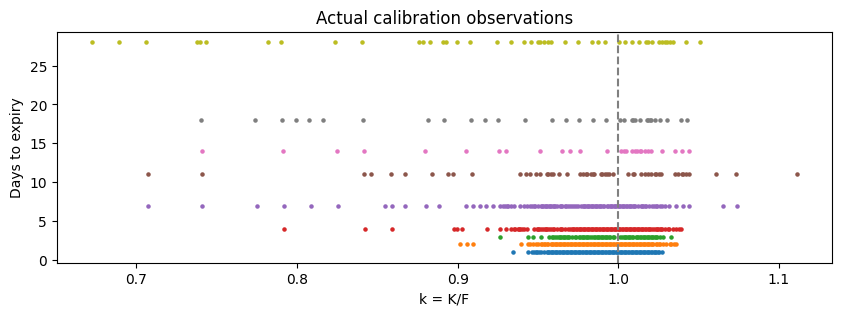

In [2]:
assert np.allclose(quotes.k,quotes.strike/quotes.forward)
fig,ax=plt.subplots(figsize=(10,3))
for e,g in quotes.groupby('exdate'):ax.scatter(g.k,g.dte,s=5)
ax.axvline(1,color='gray',ls='--');ax.set(xlabel='k = K/F',ylabel='Days to expiry',title='Actual calibration observations');plt.show()

## 2. 报价筛选

成交量至少100、Vega/√T至少0.001、每期限至少20个有效点；项目另限制1–120日、k≥0.45。这里只展示筛选后的真实样本，不将被排除的报价画成拟合目标。下表不是原始数据到筛选数据的流失统计。

In [3]:
selection=quotes.groupby(['exdate','dte']).agg(quotes=('k','size'),min_k=('k','min'),max_k=('k','max'),min_volume=('volume','min'))
display(selection)
assert quotes.volume.ge(100).all()
assert quotes.source_vega_over_sqrt_t.ge(.001).all()
assert quotes.groupby('exdate').size().ge(20).all()

,,quotes,min_k,max_k,min_volume
exdate,dte,,,,
2025-06-03,1,94,0.934335,1.027011,103
2025-06-04,2,102,0.901423,1.036215,108
2025-06-05,3,76,0.926659,1.032804,100
2025-06-06,4,112,0.791670,1.039277,100
2025-06-09,7,115,0.707411,1.073749,102
2025-06-13,11,54,0.707052,1.111082,105
2025-06-16,14,28,0.740752,1.043787,100
2025-06-20,18,33,0.740242,1.043068,100
2025-06-30,28,46,0.672413,1.050645,100


## 3. 方差骨架与平滑

骨架来自 ATM call bid IV，必要时单调化；核方差为 eta 乘骨架方差。eta 是诊断设置。

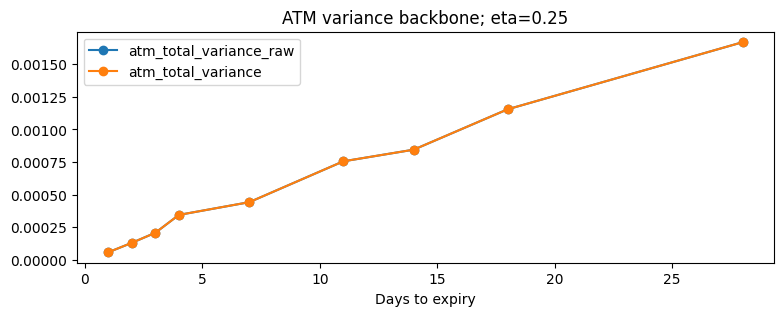

In [4]:
backbone=quotes.groupby('dte')[['atm_total_variance_raw','atm_total_variance']].first()
backbone.plot(marker='o',figsize=(9,3),title=f'ATM variance backbone; eta={summary["eta"]}')
plt.xlabel('Days to expiry');plt.show()

## 4. 联合 LP 的价格拟合

求非负混合权重 q，保持总质量、均值为1，并施加期限间凸序。目标主要惩罚 bid–ask 外误差，而不是要求穿过全部中间价。下面选择当前最长有效期限。

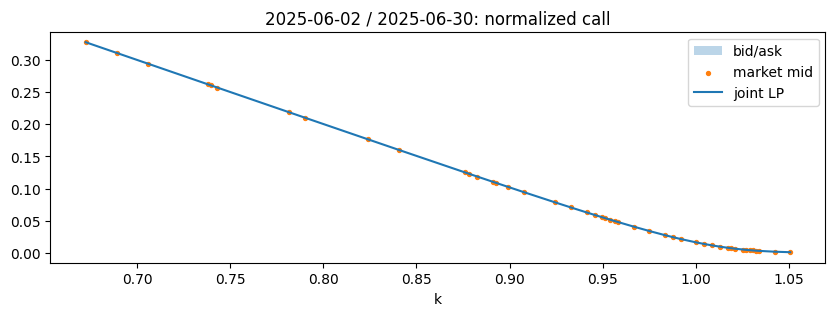

In [5]:
EXPIRY=quotes.sort_values('dte').exdate.iloc[-1]
g=quotes[quotes.exdate==EXPIRY].sort_values('k')
fig,ax=plt.subplots(figsize=(10,3))
ax.fill_between(g.k,g.pure_bid,g.pure_ask,alpha=.3,label='bid/ask')
ax.scatter(g.k,g.pure_mid,s=8,label='market mid');ax.plot(g.k,g.fit,label='joint LP')
ax.set(title=f'{DATE} / {EXPIRY}: normalized call',xlabel='k');ax.legend();plt.show()

## 5. 隐含波动率切片

每个期限只画参与拟合的报价，模型线限制在该期限的报价范围内。IV 由 OTM 价格稳定反解；无效数值保留为缺口，不用 Vega 阈值掩盖曲线。

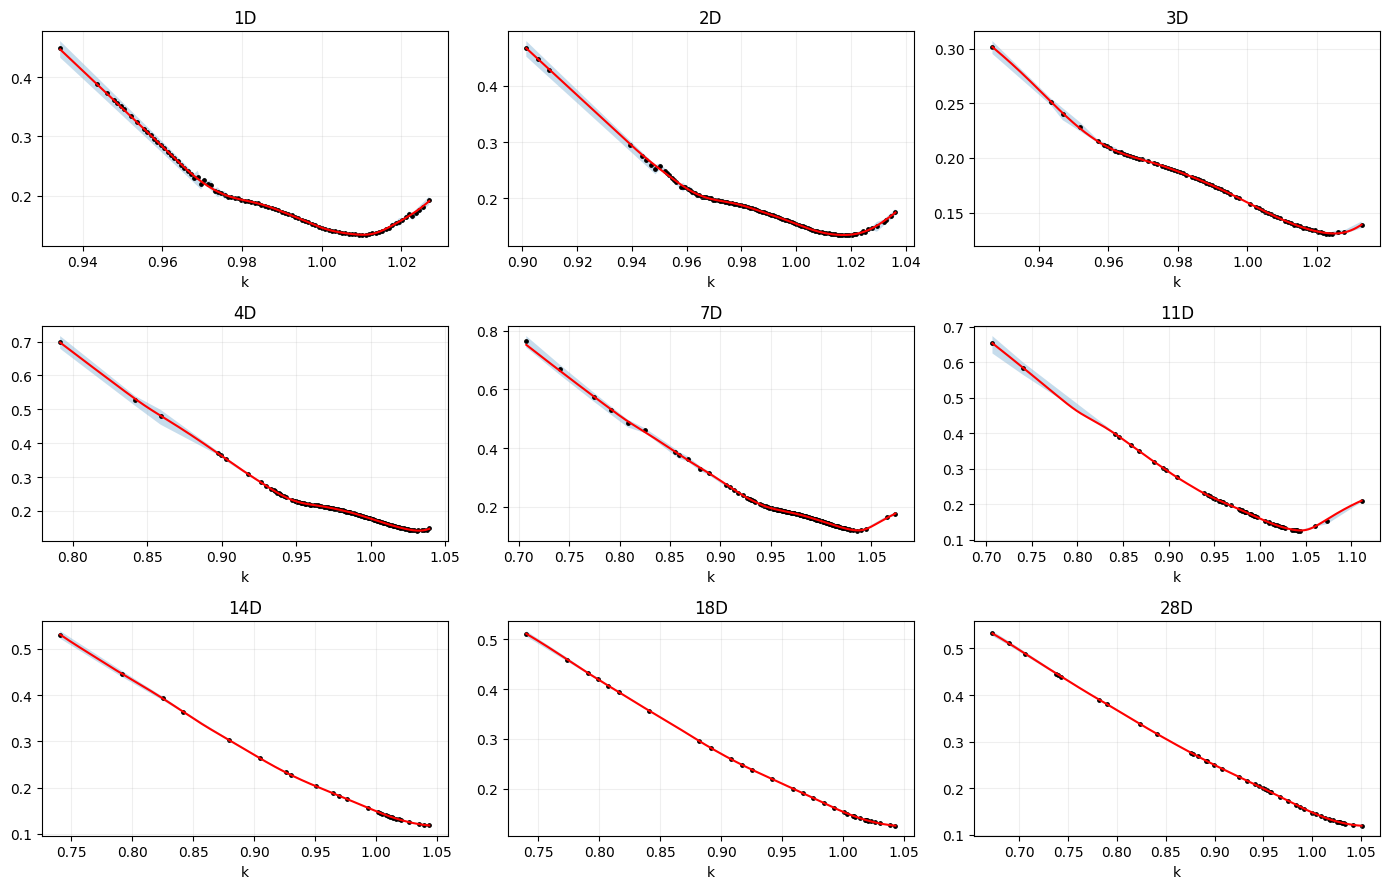

In [6]:
expiries=sorted(quotes.exdate.unique())
fig,axs=plt.subplots(int(np.ceil(len(expiries)/3)),3,figsize=(14,3*np.ceil(len(expiries)/3)),squeeze=False)
for ax,e in zip(axs.flat,expiries):
    f=quotes[quotes.exdate==e].sort_values('k');T=float(model[e+'__T'])
    k=np.linspace(f.k.min(),f.k.max(),501)
    v=iv(k,otm(k,model[e+'__anchors'],float(model[e+'__smooth_variance']),model[e+'__q']),T)
    intrinsic=np.maximum(1-f.k.to_numpy(),0)
    ax.fill_between(f.k,iv(f.k.to_numpy(),f.pure_bid.to_numpy()-intrinsic,T),iv(f.k.to_numpy(),f.pure_ask.to_numpy()-intrinsic,T),alpha=.25)
    ax.scatter(f.k,f.source_otm_iv,s=6,c='black');ax.plot(k,v,c='red')
    ax.set_title(f'{int(f.dte.iloc[0])}D');ax.set_xlabel('k');ax.grid(alpha=.2)
for ax in list(axs.flat)[len(expiries):]:ax.set_visible(False)
fig.tight_layout();plt.show()

## 6. 混合权重与平滑后的密度

节点权重 q 不是最终连续密度。对数正态核把离散状态平滑成连续分布。下图限制在观察执行价范围；尾部没有展示完全。

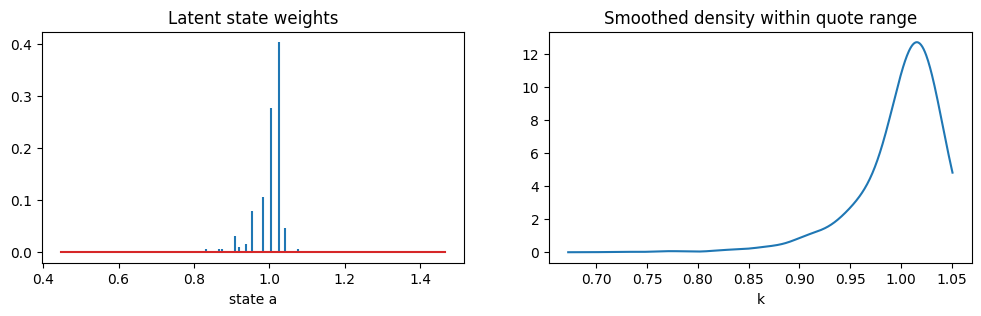

mass: 1.0 mean: 1.0 minimum q: 0.0


In [7]:
e=EXPIRY;a=model[e+'__anchors'];q=model[e+'__q'];w=float(model[e+'__smooth_variance'])
k=np.linspace(g.k.min(),g.k.max(),600);s=np.sqrt(w)
d2=(np.log(a[None,:]/k[:,None])-.5*w)/s
density=(norm.pdf(d2)/(k[:,None]*s))@q
fig,axs=plt.subplots(1,2,figsize=(12,3))
axs[0].stem(a,q,markerfmt=' ');axs[0].set(title='Latent state weights',xlabel='state a')
axs[1].plot(k,density);axs[1].set(title='Smoothed density within quote range',xlabel='k');plt.show()
print('mass:',q.sum(),'mean:',a@q,'minimum q:',q.min())

## 7. 连续价格曲面

在最短与最长期限之间插值，不做时间外推。下图只取所有有效期限共同的执行价范围；连续查询不是新的市场观察。

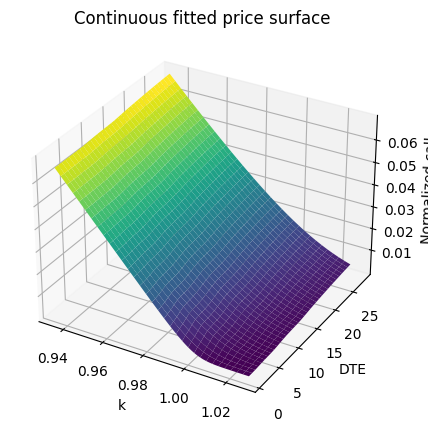

In [8]:
from sanos_surface import SanosSurface
surface=SanosSurface.from_directory(MODEL_DIR)
support=quotes.groupby('exdate').k.agg(['min','max'])
kg=np.linspace(support['min'].max(),support['max'].min(),65)
days=np.linspace(quotes.dte.min(),quotes.dte.max(),35)
kk,dd=np.meshgrid(kg,days)
prices=surface.pure_call_days(dd,kk)
fig=plt.figure(figsize=(10,5));ax=fig.add_subplot(111,projection='3d')
ax.plot_surface(kk,dd,prices,cmap='viridis',linewidth=0)
ax.set(xlabel='k',ylabel='DTE',zlabel='Normalized call',title='Continuous fitted price surface');plt.show()

## 8. 无套利数值审计与多日覆盖率

保存结果包含中间期限、执行价网格的数值审计。核心定义为 OTM 绝对远期 delta≥0.1，尚非业务批准的报价区域。数值检查和报价覆盖率不等于 Greeks 验收。

lower_price_violation           3.330669e-16
upper_price_violation           1.627587e-13
increasing_strike_violation    1.732011e-313
slope_below_minus_one           6.661338e-14
convexity_violation             1.332268e-13
calendar_violation              4.818368e-14
Name: violation, dtype: float64

,date,eta,expiries,quotes,coverage,core_coverage
3,2025-01-02,0.25,12,802,0.991272,1.0
4,2025-01-03,0.25,11,799,0.997497,1.0
5,2025-01-06,0.25,15,906,0.998896,1.0
0,2025-04-01,0.10,13,869,1.000000,1.0
1,2025-04-02,0.10,13,857,0.998833,1.0
2,2025-04-03,0.10,15,1061,0.991517,1.0
6,2025-06-02,0.25,9,660,1.000000,1.0
7,2025-06-03,0.25,10,625,1.000000,1.0
8,2025-06-04,0.25,10,608,1.000000,1.0


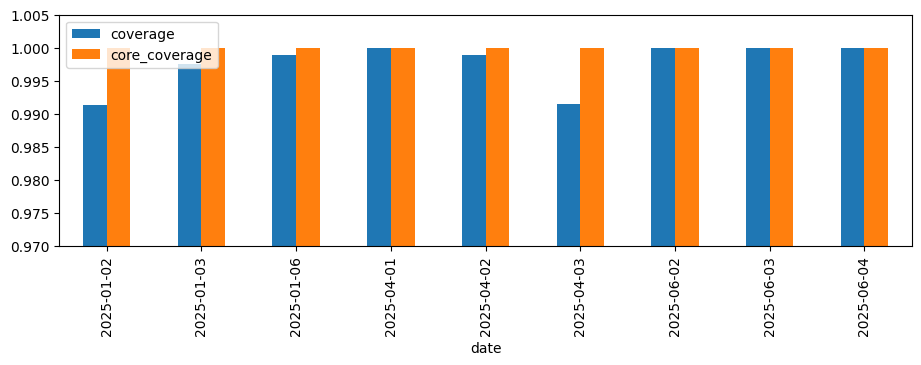

In [9]:
display(pd.Series(summary['surface_audit']['residuals'],name='violation'))
rows=[]
for p in (ROOT/'data/outputs/daily_validation').glob('*/*/lp/summary.json'):
    r=json.loads(p.read_text(encoding='utf8'))
    rows.append({k:r[k] for k in ['date','eta','expiries','quotes','coverage','core_coverage']})
results=pd.DataFrame(rows).sort_values('date');display(results)
results.set_index('date')[['coverage','core_coverage']].plot.bar(figsize=(11,3),ylim=(.97,1.005));plt.show()

## 9. 翼部边界对照

固定报价和 eta，只增加共同左尾状态0.2。已检查的3处回头消失，核心拟合保持。这是诊断对照，尚未修改默认状态范围，也不保证更极端翼部。

,date,dte,variant,success,coverage,core_coverage,left_edge_iv,left_peak_iv,left_turn_amplitude,left_peak_k,anchor_min
0,2025-01-02,88,saved_baseline,True,0.730769,1.0,0.563820,0.568397,0.004576,0.471724,0.433293
1,2025-01-02,88,add_state_020,True,1.000000,1.0,0.631350,0.631350,0.000000,0.456098,0.200000
2,2025-04-03,43,saved_baseline,True,0.971014,1.0,0.777147,0.782784,0.005637,0.475125,0.438120
3,2025-04-03,43,add_state_020,True,1.000000,1.0,0.818276,0.818276,0.000000,0.461179,0.200000
4,2025-04-03,88,saved_baseline,True,0.920000,1.0,0.608843,0.609317,0.000474,0.483541,0.438120
5,2025-04-03,88,add_state_020,True,1.000000,1.0,0.657231,0.657231,0.000000,0.477807,0.200000


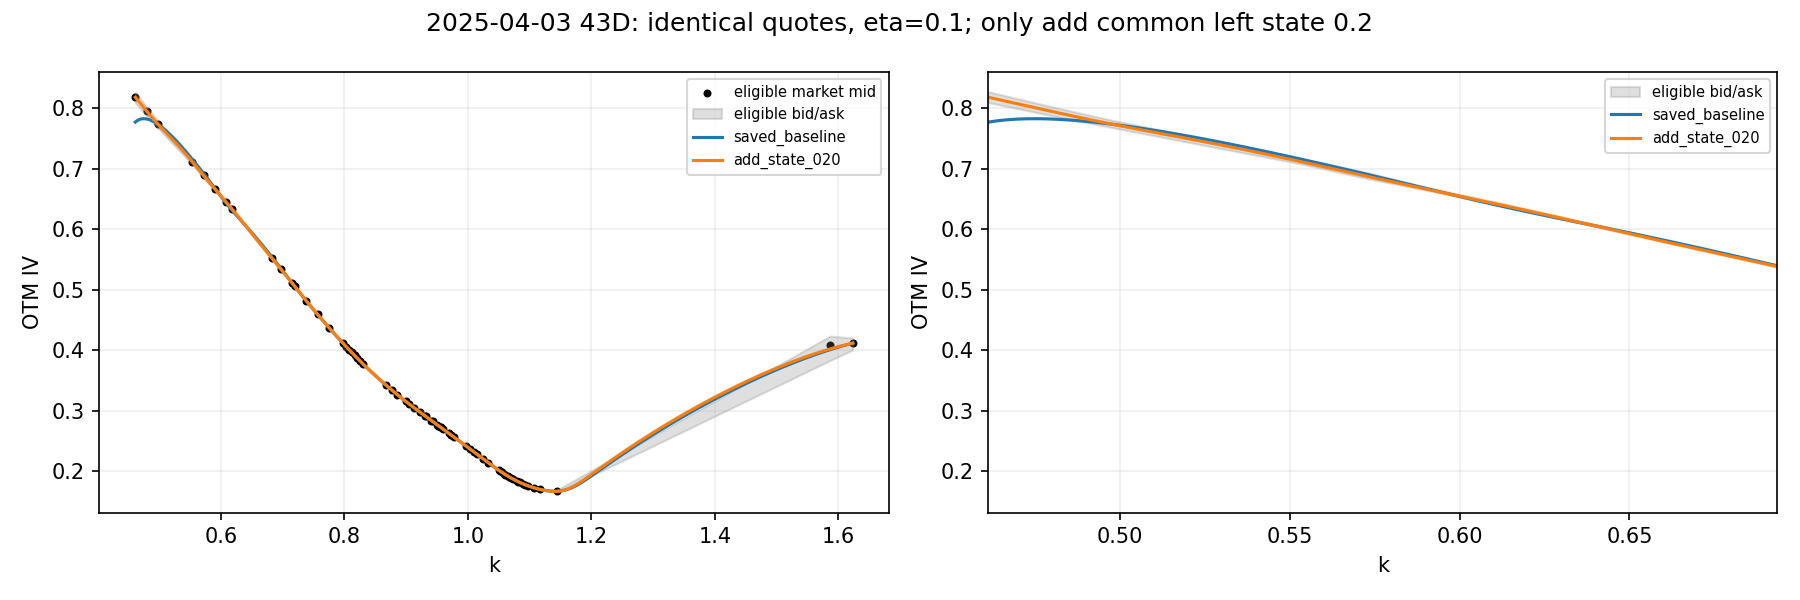

In [10]:
wing=ROOT/'data/outputs/wing_boundary'
if (wing/'summary.csv').exists():
    display(pd.read_csv(wing/'summary.csv'))
    display(Image(filename=str(wing/'2025-04-03_43D.png')))
else:
    print('可选翼部对照尚未生成：python scripts/diagnose_xtx_wing_boundary.py')

## 10. 延伸探索：广义模型、QP 与 DLV

广义模型按同一观察日的到期期限递推；核心优先是可选的两阶段 LP，先保护核心误差，再拟合翼部。跨日 QP 以先前交易日曲面为参考，研究稳定更新；DLV 研究离散局部波动率参数化及直接校准。以下只比较广义模型的目标函数，不代表基础 LP 结果，也不表示 QP 或 DLV 使用相同方法。实验范围和未解决的问题见 docs/SUMMARY.md。

core_coverage             coverage          
priority      core_first     paper core_first     paper
date                                                   
2025-04-01      0.798956  0.637076   0.661680  0.686997
2025-04-02      0.742347  0.576531   0.578763  0.624271
2025-06-03      1.000000  0.992593   0.921600  0.992000

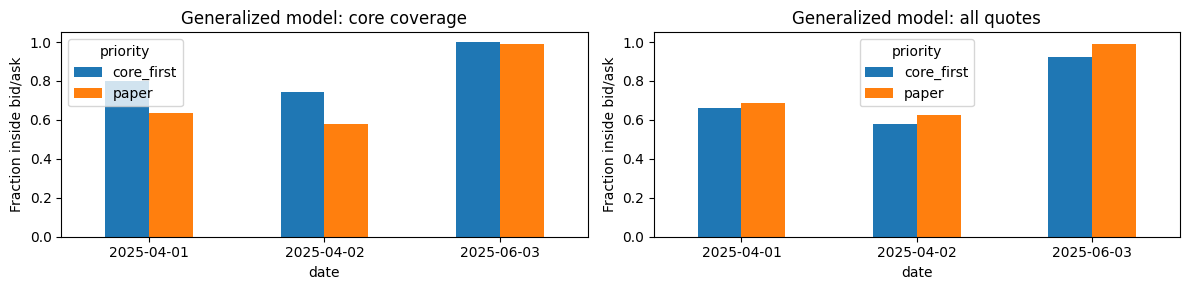

In [11]:
priority_path=ROOT/'data/outputs/research_exploration/core_priority/results.csv'
if priority_path.exists():
    priority=pd.read_csv(priority_path)
    comparison=priority[priority.experiment.eq('entire_recursion')].pivot(
        index='date',columns='priority',values=['core_coverage','coverage'])
    display(comparison)
    fig,axs=plt.subplots(1,2,figsize=(12,3))
    for ax,metric,title in zip(axs,['core_coverage','coverage'],['Generalized model: core coverage','Generalized model: all quotes']):
        comparison[metric].plot.bar(ax=ax,ylim=(0,1.05),title=title,rot=0)
        ax.set_ylabel('Fraction inside bid/ask')
    fig.tight_layout();plt.show()
else:
    print('可选目标对照尚未生成：python scripts/explore_xtx_core_priority.py')

## 11. 当前结论与后续研究

基础 LP 的9天验证已跑通；3处翼部问题已有状态边界对照。跨日 QP 是稳定更新拓展，广义增量和状态转移仍是研究成果。尚需统一报价区域、Greeks 和盘中验证；不把收盘拟合通过等同于生产完成。